# Wadi Ghadir gravity survey – step-by-step processing

**Wadi Ghadir, Eastern Desert, Egypt · Scintrex CG-6 relative gravity (#0640, #0313) · 16–24 January 2026**

**Prepared by Dr. Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook processes the gravity data from the raw instrument files to the final anomaly maps. Each step
loads or processes the data, shows the result as tables and plots, and has parameters you can adapt.

| Step | Content |
|---:|---|
| 1 | Load the CG-6 data and inventory the files |
| 2 | Check the on-board corrections |
| 3 | Earth tide correction |
| 4 | Quality control of every reading |
| 5 | Station occupations |
| 6 | GNSS positions and matching |
| 7 | Heights: EGM2008 geoid and DEM |
| 8 | Base control and drift correction |
| 9 | Inter-instrument calibration |
| 10 | Free-air and Bouguer anomalies |
| 11 | Terrain correction and complete Bouguer anomaly |
| 12 | Density: Nettleton method |
| 13 | Gridding and anomaly maps |
| 14 | Export of the results and publication figures |


**How to use this notebook**

* Run the cells from top to bottom (*Run → Run All Cells*), or one step at a time with *Shift + Enter*.
* Every step has up to three cells:
  * **✏️ PARAMETERS**: values you may change, such as thresholds, densities or grid spacing.
  * **▶ PROCESSING**: calls the processing functions of the `wghadir` package.
  * **📊 RESULT**: tables and plots of the result of that step.
* After changing a parameter, re-run that step **and all steps below it**, because each step uses the
  results of the previous ones.
* To change *how* a step works, open the function named in its processing cell, e.g. `qc.row_qc` in
  `wghadir/gravity/qc.py`.
* The default parameters reproduce the delivered results exactly.

## 0  Set-up

In [1]:
%matplotlib inline
import json
import os
import sys
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# make the wghadir package importable (repository layout: this notebook is in notebooks/)
REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from wghadir.common import geodata, mapping
from wghadir.gravity import (base_control, density, export, figures, instruments, inventory, positioning, qc,
                             reductions, settings, terrain)
from wghadir.gravity import maps as gmaps

# ✏️ input and output folders
RAW_DIR = os.path.join(REPO, "data", "raw")             # CG-6 .dat files, GNSS workbooks and KML (as supplied)
EXTERNAL_DIR = os.path.join(REPO, "data", "external")   # DEM and geoid (downloaded on first use)
OUT_DIR = os.path.join(REPO, "outputs")                 # results are written here
TABLE_DIR = os.path.join(OUT_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)


def save_table(df, name):
    """Write a processing table to outputs/tables."""
    df.to_csv(os.path.join(TABLE_DIR, name), index=False, float_format="%.6g")


COLOR = mapping.INST_COL          # instrument colours used in all plots
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("ready – raw data in", os.path.abspath(RAW_DIR))

ready – raw data in /home/user/MooSobh/data/raw


## 1  Load the CG-6 data

The two CG-6 exports are read completely (`inventory.load_instruments`); readings taken at one station
without a long break are grouped by an occupation id. The file inventory lists every raw file with its
SHA-256 checksum, and the CG-6 header provides the instrument metadata.

In [2]:
# ✏️ PARAMETERS – edit and re-run from here
INSTRUMENT_FILES = settings.INSTRUMENT_FILES    # {instrument: file name in RAW_DIR}
INSTRUMENT_FILES

{'CG6-0640': 'CG-6_0640_W_GHADIR_New_gravimeter.dat',
 'CG6-0313': 'CG-6_0313_W_GHADER_old_gravimeter.dat'}

In [3]:
# ▶ PROCESSING
headers, rows = inventory.load_instruments(RAW_DIR)
files, meta = inventory.inventory_tables(headers, rows, RAW_DIR)
save_table(files, "01_file_inventory.csv")
save_table(meta, "02_instrument_metadata.csv")
print(f"{len(rows)} readings loaded")
display(files)
display(meta.T)
rows.groupby(["Date", "instrument"]).size().unstack().fillna(0).astype(int)

1519 readings loaded


,file,bytes,sha256
0,Astra_processing_prompt.md,7738,38f1733ea251b9c2dff227af0a784a3bb5caf42b962b77...
1,CG-6_0313_W_GHADER_old_gravimeter.dat,129588,c4ee0ba3059fbf1636ec01c5986c716b0f4266a52ba928...
2,CG-6_0640_W_GHADIR_New_gravimeter.dat,138508,5495ae79b0678a593811457464db9c1f33978f82fd78b5...
3,GPS_All_Days.xlsx,59581,cfaf07bce7d119613f4e56fc03b89290ab58ca1bc9ed48...
4,results.zip,186531,06ec74fc322b36b94a6653b4159e26c284d8b2a7444470...


,0,1
instrument,CG6-0640,CG6-0313
file,CG-6_0640_W_GHADIR_New_gravimeter.dat,CG-6_0313_W_GHADER_old_gravimeter.dat
bytes,138508,129588
sha256,5495ae79b0678a593811457464db9c1f33978f82fd78b5...,c4ee0ba3059fbf1636ec01c5986c716b0f4266a52ba928...
survey_name,W_GHADIR,W_GHADER
serial,000000024110640,000000021010313
created,2026-01-16 03:52:49,2026-01-16 03:54:27
operator,NRIAG,NRIAG
firmware,CG6_2_20240409,CG6_2_20240409
gcal1_mgal,8323.669000,7869.544000


instrument,CG6-0313,CG6-0640
Date,,
2026-01-16,149,148
2026-01-17,61,70
2026-01-18,64,95
2026-01-19,39,69
2026-01-20,58,99
2026-01-21,62,52
2026-01-22,93,95
2026-01-23,110,105
2026-01-24,88,62


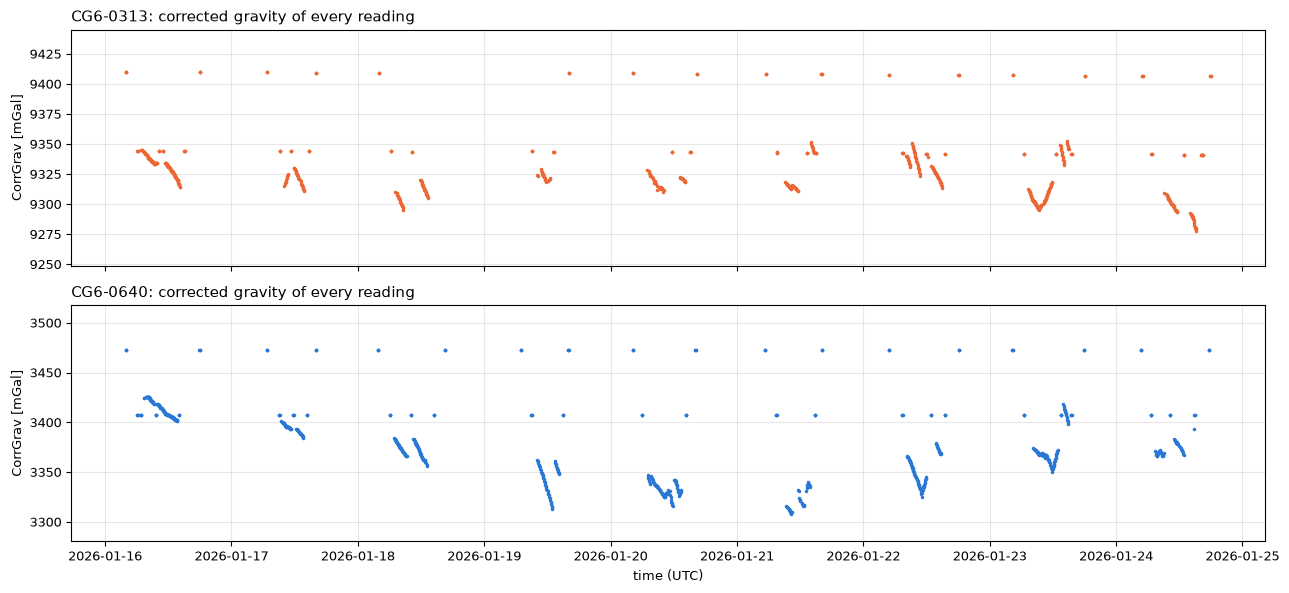

In [4]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, (inst, d) in zip(axes, rows.groupby("instrument")):
    ax.plot(d["time_utc"], d["CorrGrav"], ".", ms=3, color=COLOR[inst])
    ax.set_ylabel("CorrGrav [mGal]")
    ax.set_title(f"{inst}: corrected gravity of every reading", loc="left")
    lo, hi = d["CorrGrav"].quantile([0.05, 0.95])
    ax.set_ylim(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo))      # robust limits: frozen/gross readings fall outside
axes[-1].set_xlabel("time (UTC)")
plt.tight_layout()

## 2  Check the on-board corrections

The CG-6 computes `CorrGrav = RawGrav + TideCorr + TiltCorr + TempCorr + DriftCorr`. This step checks the
sum for every reading (`inventory.verify_corrgrav`). Because it closes, each term can later be replaced on its
own (the tide in step 3, the drift in step 8).

In [5]:
# ▶ PROCESSING
corrgrav_check = inventory.verify_corrgrav(rows)
save_table(corrgrav_check, "03_corrgrav_verification.csv")
corrgrav_check

,instrument,rows_checked,rows_with_overflow,closure_rms_mgal,closure_max_abs_mgal,equation,mean_tide,mean_temp,mean_tilt,mean_drift
0,CG6-0313,724,1,0.000067,0.0002,CorrGrav = RawGrav + TideCorr + TiltCorr + Tem...,-0.021269,0.270644,0.0007,-739.629519
1,CG6-0640,795,2,0.000065,0.0002,CorrGrav = RawGrav + TideCorr + TiltCorr + Tem...,-0.004242,0.492939,0.0010,0.000000


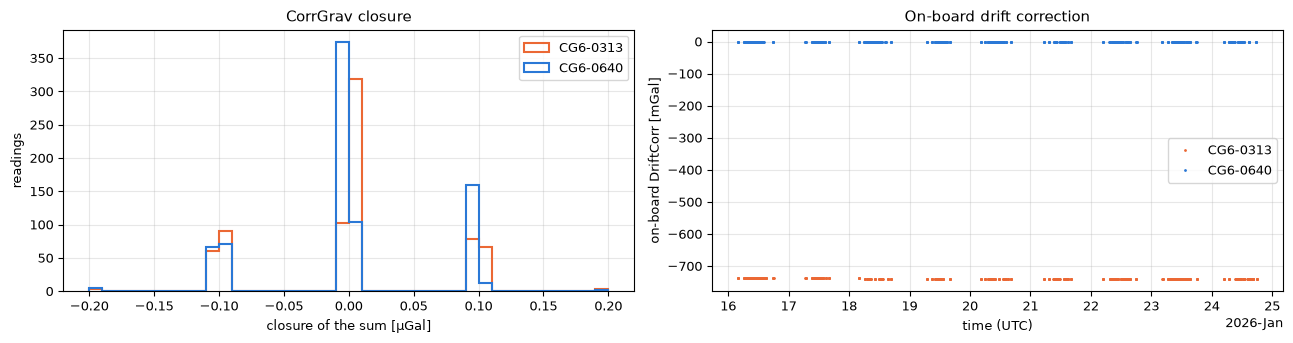

In [6]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for inst, d in rows.groupby("instrument"):
    axes[0].hist(1000 * d["corrgrav_closure_mgal"].dropna(), bins=40, histtype="step", lw=1.5,
                 color=COLOR[inst], label=inst)
    axes[1].plot(d["time_utc"], d["DriftCorr"], ".", ms=2, color=COLOR[inst], label=inst)
axes[0].set(xlabel="closure of the sum [µGal]", ylabel="readings", title="CorrGrav closure")
axes[1].set(xlabel="time (UTC)", ylabel="on-board DriftCorr [mGal]", title="On-board drift correction")
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axes[1].xaxis.get_major_locator()))
for ax in axes:
    ax.legend()
plt.tight_layout()

## 3  Earth tide correction

The on-board tide is recomputed with the Longman (1959) formula (`inventory.tide_recompute`). It matches the
CG-6 value when the time stamps are taken as **UTC** at the user-entered position. For #0313 that position was
left at Toronto, so for both instruments the tide is recomputed at the **CG-6 GPS position**:

`g_tidefix = CorrGrav − TideCorr + tide(GPS position)`

In [7]:
# ▶ PROCESSING
tide_check = inventory.tide_recompute(rows)      # adds tide_longman_gps and g_tidefix to rows
save_table(tide_check, "04_tide_check.csv")
tide_check

,instrument,model,rms_ugal,max_abs_ugal
0,CG6-0313,"Longman at user-entered position, t as UTC",0.208277,0.419939
1,CG6-0313,"Longman at CG-6 GPS position, t as UTC",89.635109,215.077120
2,CG6-0313,"Longman at user position, t shifted -3 h",73.853237,134.167015
3,CG6-0313,"Longman at user position, t shifted -2 h",50.309270,92.844010
4,CG6-0313,"Longman at user position, t shifted +2 h",48.744666,93.288906
5,CG6-0313,"Longman at user position, t shifted +3 h",68.261942,134.598188
6,CG6-0640,"Longman at user-entered position, t as UTC",0.193739,0.433270
7,CG6-0640,"Longman at CG-6 GPS position, t as UTC",1.830581,3.115111
8,CG6-0640,"Longman at user position, t shifted -3 h",70.043101,152.495267
9,CG6-0640,"Longman at user position, t shifted -2 h",49.998658,98.930594


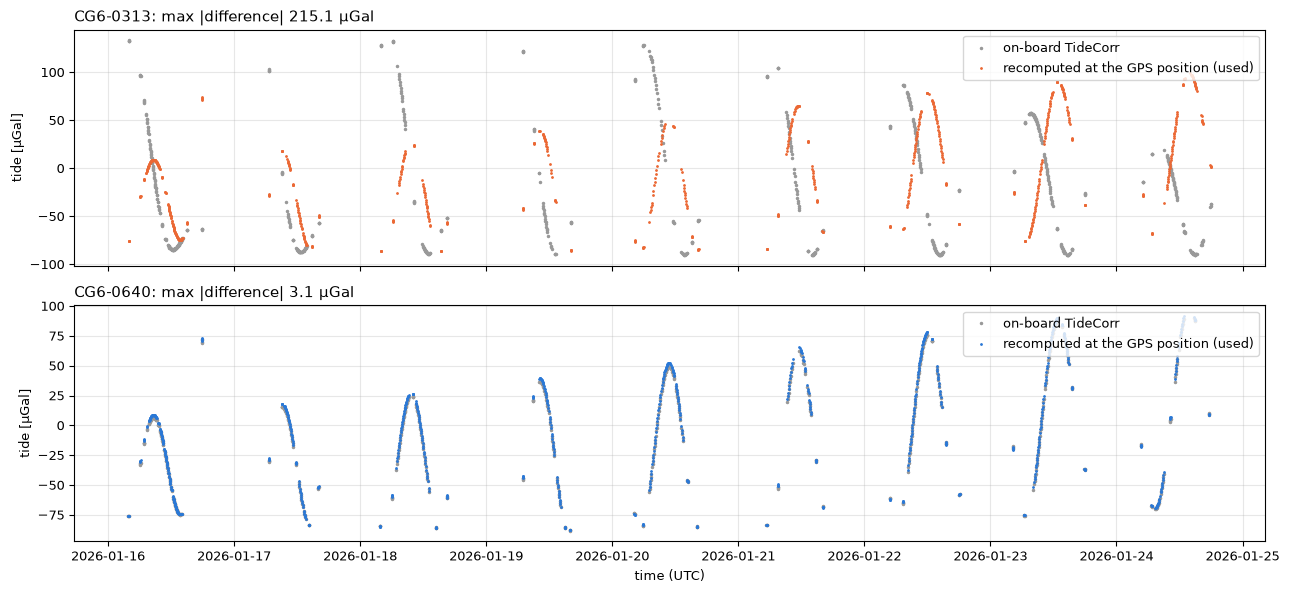

In [8]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, (inst, d) in zip(axes, rows.groupby("instrument")):
    ax.plot(d["time_utc"], 1000 * d["TideCorr"], ".", ms=3, color="0.6", label="on-board TideCorr")
    ax.plot(d["time_utc"], 1000 * d["tide_longman_gps"], ".", ms=2, color=COLOR[inst],
            label="recomputed at the GPS position (used)")
    ax.set_ylabel("tide [µGal]")
    ax.set_title(f"{inst}: max |difference| {1000 * d['tide_replacement_mgal'].abs().max():.1f} µGal", loc="left")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("time (UTC)")
plt.tight_layout()

## 4  Quality control of every reading

`qc.row_qc` keeps every reading and gives it an accept/reject decision with reasons:

* overflow fields (`******`) in the export;
* frozen sensor output of #0313 (RawGrav 8007.5–8009.0 mGal);
* gross values: |g − instrument median| above `gross_range_mgal`;
* noise: StdDev above `stddev_reject_mgal` (between the warn and reject limits gives a warning only);
* tilt: max(|X|, |Y|) above `tilt_reject_arcsec`;
* repeat outliers: deviation from the median of the other readings at the same station above `repeat_outlier_mgal`.

**Try it:** change `stddev_reject_mgal` to 0.05 and re-run to see how many more readings are rejected.

In [9]:
# ✏️ PARAMETERS – edit and re-run from here
TH = dict(settings.THRESHOLDS)     # copy of the default thresholds – edit any value
# TH["stddev_reject_mgal"] = 0.050
# TH["tilt_reject_arcsec"] = 20.0
TH

{'stddev_reject_mgal': 0.08,
 'stddev_warn_mgal': 0.05,
 'tilt_reject_arcsec': 30.0,
 'tilt_warn_arcsec': 20.0,
 'repeat_outlier_mgal': 0.05,
 'repeat_range_warn_mgal': 0.05,
 'gps_spread_warn_m': 50.0,
 'gross_range_mgal': 500.0}

In [10]:
# ▶ PROCESSING
rows = qc.row_qc(rows, th=TH)
qc_sensitivity = qc.threshold_sensitivity(rows)
save_table(qc_sensitivity, "06_qc_threshold_sensitivity.csv")
save_table(pd.DataFrame([TH]), "06_qc_thresholds.csv")
print(f"accepted {rows['accepted'].sum()} of {len(rows)} readings")
rows.loc[~rows["accepted"], "reject_reasons"].value_counts().rename("rejected readings").to_frame()

accepted 1472 of 1519 readings


,rejected readings
reject_reasons,
FROZEN_SENSOR_OUTPUT,27
REPEAT_OUTLIER,8
STDDEV_GT_0.080,4
TILT_GT_30,3
OVERFLOW_FIELD;GROSS_RANGE_GT_500;TILT_GT_30,2
GROSS_RANGE_GT_500,1
GROSS_RANGE_GT_500;TILT_GT_30,1
OVERFLOW_FIELD,1


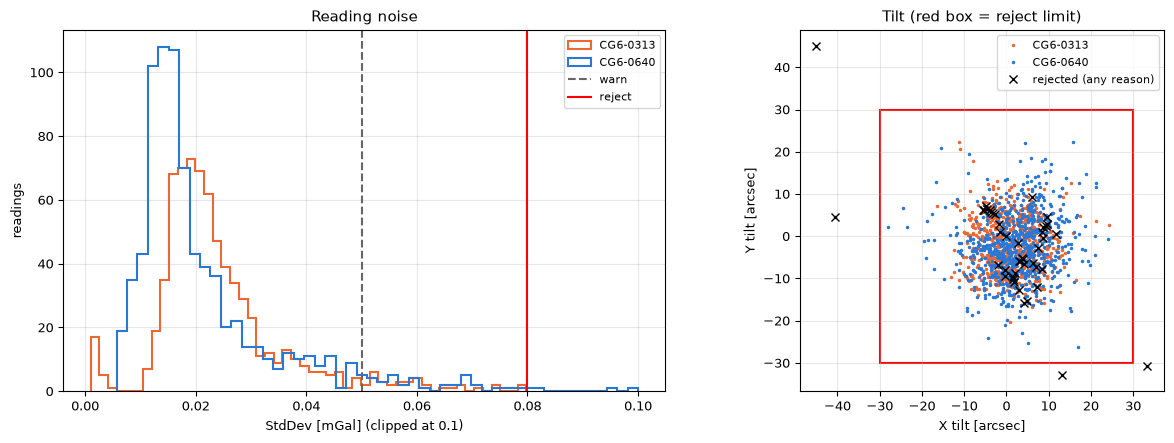

In [11]:
# 📊 RESULT
ok = rows["overflow_fields"].eq("")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for inst, d in rows[ok].groupby("instrument"):
    axes[0].hist(d["StdDev"].clip(upper=0.1), bins=50, histtype="step", lw=1.5, color=COLOR[inst], label=inst)
    axes[1].plot(d["X"].clip(-45, 45), d["Y"].clip(-45, 45), ".", ms=3, color=COLOR[inst], label=inst)
axes[0].axvline(TH["stddev_warn_mgal"], color="0.4", ls="--", label="warn")
axes[0].axvline(TH["stddev_reject_mgal"], color="r", label="reject")
axes[0].set(xlabel="StdDev [mGal] (clipped at 0.1)", ylabel="readings", title="Reading noise")
t = TH["tilt_reject_arcsec"]
axes[1].add_patch(plt.Rectangle((-t, -t), 2 * t, 2 * t, fill=False, ec="r", lw=1.5))
rej = rows[~rows["accepted"] & ok]
axes[1].plot(rej["X"].clip(-45, 45), rej["Y"].clip(-45, 45), "kx", ms=6, label="rejected (any reason)")
axes[1].set(xlabel="X tilt [arcsec]", ylabel="Y tilt [arcsec]", title="Tilt (red box = reject limit)", aspect="equal")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()

## 5  Station occupations

`inventory.build_occupations` combines the accepted readings at one station into one value per occupation:
the mean of `g_tidefix`, and as uncertainty the larger of the internal standard error and the scatter of the
repeated readings.

In [12]:
# ▶ PROCESSING
occ = inventory.build_occupations(rows)
print(f"{len(occ)} occupations, {occ['usable'].sum()} with at least one accepted reading")
display(occ.groupby(["instrument", "role"]).agg(occupations=("occ_id", "size"), usable=("usable", "sum")))
occ[["occ_key", "n_readings", "n_accepted", "g_occ", "sigma_occ", "occ_flags"]].head(8)

1116 occupations, 1094 with at least one accepted reading


occupations  usable
instrument role                               
CG6-0313   field                   466     457
           field_base_100           29      26
           hotel_base_0             18      16
CG6-0640   field                   559     551
           field_base_100           26      26
           hotel_base_0             18      18

,occ_key,n_readings,n_accepted,g_occ,sigma_occ,occ_flags
0,CG6-0313|2026-01-16|L0|S0,4,4,9409.400169,0.003336,
1,CG6-0313|2026-01-16|L0|S100,4,4,9344.079462,0.003175,
2,CG6-0313|2026-01-16|L0|S100,4,4,9344.637335,0.002657,
3,CG6-0313|2026-01-16|L2|S1,2,2,9343.968248,0.023644,
4,CG6-0313|2026-01-16|L2|S2,2,2,9343.679104,0.010696,
5,CG6-0313|2026-01-16|L2|S3,2,2,9343.117499,0.001840,
6,CG6-0313|2026-01-16|L2|S4,2,2,9342.398678,0.011978,
7,CG6-0313|2026-01-16|L2|S5,2,2,9341.886503,0.006181,


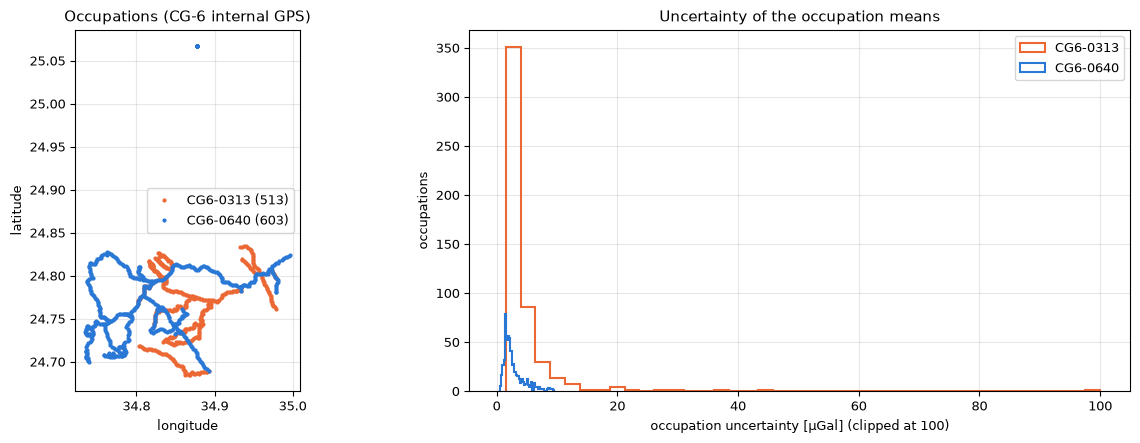

In [13]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for inst, d in occ.groupby("instrument"):
    axes[0].plot(d["lon_cg6"], d["lat_cg6"], ".", ms=4, color=COLOR[inst], label=f"{inst} ({len(d)})")
    axes[1].hist(1000 * d["sigma_occ"].dropna().clip(upper=0.1), bins=40, histtype="step", lw=1.5,
                 color=COLOR[inst], label=inst)
axes[0].set(xlabel="longitude", ylabel="latitude", title="Occupations (CG-6 internal GPS)",
            aspect=1 / np.cos(np.radians(24.76)))
axes[1].set(xlabel="occupation uncertainty [µGal] (clipped at 100)", ylabel="occupations",
            title="Uncertainty of the occupation means")
for ax in axes:
    ax.legend()
plt.tight_layout()

## 6  GNSS positions and station matching

The GNSS point workbooks (in `results.zip`), the master workbook and the KML files are read
(`positioning.load_gnss`). The heights of each GNSS day are checked at the two base marks; a day whose two marks
are both offset by more than `DAY_SHIFT_MIN_M` with the same sign is corrected (`positioning.gnss_datum_check`).
GNSS days are mapped to gravity dates by coordinates (`positioning.map_days`). Then every occupation is matched to
one GNSS point of its day (`positioning.match_occupations`):

* the nearest point within `max_dist_m` of the CG-6 GPS position;
* *ambiguous* if a second point at a different location (more than `distinct_loc_m` away) lies within
  nearest distance + `ambig_margin_m`; resolved only when the station ID identifies one of them.

In [14]:
# ✏️ PARAMETERS – edit and re-run from here
DAY_SHIFT_MIN_M = settings.DAY_DATUM_SHIFT_MIN_M          # 0.5 m
MATCH = dict(max_dist_m=settings.MATCH_MAX_M,             # 30 m
             ambig_margin_m=settings.AMBIG_MARGIN_M,      # 10 m
             distinct_loc_m=settings.DISTINCT_LOC_M)      # 5 m
MATCH

{'max_dist_m': 30.0, 'ambig_margin_m': 10.0, 'distinct_loc_m': 5.0}

In [15]:
# ▶ PROCESSING
gnss_points, kml_points, master_check, zip_list = positioning.load_gnss(RAW_DIR)
datum_marks, datum_days, ref = positioning.gnss_datum_check(gnss_points, shift_min_m=DAY_SHIFT_MIN_M)
day_map, day_of_date = positioning.map_days(occ, gnss_points)
occ = positioning.match_occupations(occ, gnss_points, day_of_date, datum_days, ref, **MATCH)

# height of base 100: median of the daily GNSS solutions after the day correction
b = datum_marks[datum_marks["mark"] == "base_100"].merge(datum_days[["gnss_day", "day_height_shift_m"]], on="gnss_day")
ref["base_100"]["h_used"] = float((b["h_gnss"] - b["day_height_shift_m"]).median())
ref["base_100"]["h_used_sd"] = float((b["h_gnss"] - b["day_height_shift_m"]).std(ddof=1))
gnss_points["date"] = gnss_points["gnss_day"].map({v: k for k, v in day_of_date.items()})

for df, name in ((zip_list, "01b_results_zip_members.csv"), (day_map, "08_gnss_day_mapping.csv"),
                 (datum_marks, "09_gnss_base_marks_by_day.csv"), (datum_days, "09_gnss_day_datum.csv")):
    save_table(df, name)
print(f"{len(gnss_points)} GNSS points; base 100: {ref['base_100']}")
display(datum_days[["gnss_day", "dh_hotel0_m", "dh_base100_m", "day_height_shift_m", "rule"]])
occ.groupby(["match_status", "instrument"]).size().unstack().fillna(0).astype(int)

1031 GNSS points; base 100: {'h': np.float64(111.77), 'lat': np.float64(24.786748811111114), 'lon': np.float64(34.9337552), 'h_used': 111.77, 'h_used_sd': 0.170317362212685}


,gnss_day,dh_hotel0_m,dh_base100_m,day_height_shift_m,rule
0,1,0.104,0.115000,0.000,no adjustment
1,2,-0.024,0.022000,0.000,no adjustment
2,3,0.026,-0.003000,0.000,no adjustment
3,4,0.000,-0.202000,0.000,no adjustment
4,5,-0.018,-0.016000,0.000,no adjustment
5,6,0.055,-0.267000,0.000,no adjustment
6,7,2.509,3.155000,2.832,both base marks offset > 0.5 m with equal sign...
7,8,-0.002,0.000000,0.000,no adjustment
8,9,-0.011,0.041073,0.000,no adjustment


instrument,CG6-0313,CG6-0640
match_status,,
MATCHED,505,577
MATCHED_ID_TIEBREAK,5,5
UNMATCHED_GT_30M,3,21


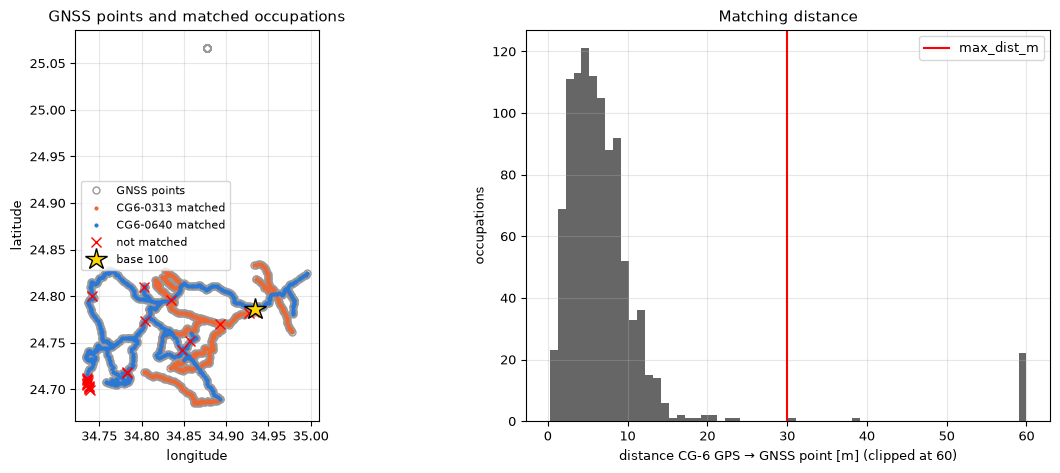

In [16]:
# 📊 RESULT
f = occ[occ["role"] == "field"]
matched = f["match_status"].isin(settings.MATCH_OK)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(gnss_points["lon"], gnss_points["lat"], "o", ms=5, mfc="none", mec="0.6", label="GNSS points")
for inst, d in f[matched].groupby("instrument"):
    ax.plot(d["lon"], d["lat"], ".", ms=4, color=COLOR[inst], label=f"{inst} matched")
ax.plot(f.loc[~matched, "lon_cg6"], f.loc[~matched, "lat_cg6"], "rx", ms=7, label="not matched")
ax.plot(ref["base_100"]["lon"], ref["base_100"]["lat"], "*", ms=16, mfc="gold", mec="k", label="base 100")
ax.set(xlabel="longitude", ylabel="latitude", title="GNSS points and matched occupations",
       aspect=1 / np.cos(np.radians(24.76)))
ax.legend(fontsize=8)
axes[1].hist(f["match_dist_m"].clip(upper=60), bins=60, color="0.4")
axes[1].axvline(MATCH["max_dist_m"], color="r", label="max_dist_m")
axes[1].set(xlabel="distance CG-6 GPS → GNSS point [m] (clipped at 60)", ylabel="occupations",
            title="Matching distance")
axes[1].legend()
plt.tight_layout()

## 7  Heights: EGM2008 geoid and Copernicus DEM

The GNSS heights are ellipsoidal. Orthometric heights are `H = h − N`, with the EGM2008 geoid undulation N
(`positioning.add_orthometric`). The Copernicus GLO-30 DEM (also referred to EGM2008) gives an independent
height check and is used for the terrain correction in step 11. Both grids are read from `data/external/` and
downloaded on first use (`geodata.fetch_dem`, `geodata.fetch_geoid`).

In [17]:
# ✏️ PARAMETERS – edit and re-run from here
DEM_BOUNDS = settings.DEM_BOUNDS     # lon0, lat0, lon1, lat1 – survey area + 22 km for the terrain correction

In [18]:
# ▶ PROCESSING
dem_path = geodata.fetch_dem(DEM_BOUNDS, os.path.join(EXTERNAL_DIR, settings.DEM_FILE))
geoid_path = geodata.fetch_geoid(DEM_BOUNDS, os.path.join(EXTERNAL_DIR, settings.GEOID_FILE))
dem, geoid = geodata.Grid(dem_path), geodata.Grid(geoid_path)
occ = positioning.add_orthometric(occ, ref, geoid, dem)

f = occ[(occ["role"] == "field") & occ["match_status"].isin(settings.MATCH_OK)]
by_day = f.groupby("gnss_day")
height_check = by_day.agg(n=("H_minus_dem_m", "size"), median_H_minus_dem=("H_minus_dem_m", "median"),
                          mad_H_minus_dem=("H_minus_dem_m", lambda v: (v - v.median()).abs().median()),
                          day_shift_applied=("day_height_shift_m", "first")).reset_index()
height_check.insert(2, "median_h_ellip_minus_dem", [np.median(d["h_gnss_original"] - d["H_dem_m"]) for _, d in by_day])
height_check["median_N_egm2008"] = [d["N_egm2008_m"].median() for _, d in by_day]
height_check["median_H_minus_dem_without_day_shift"] = height_check["median_H_minus_dem"] + height_check["day_shift_applied"]
height_datum = dict(median_h_ellipsoidal_minus_dem=float(np.median(f["h_gnss_original"] - f["H_dem_m"])),
                    median_N_egm2008=float(f["N_egm2008_m"].median()),
                    N_range=[float(f["N_egm2008_m"].min()), float(f["N_egm2008_m"].max())],
                    median_H_minus_dem=float(f["H_minus_dem_m"].median()),
                    mad_H_minus_dem=float((f["H_minus_dem_m"] - f["H_minus_dem_m"].median()).abs().median()))
save_table(height_check, "21_height_datum_dem_check.csv")
save_table(gnss_points.drop(columns=["lat_text", "lon_text"], errors="ignore"), "07_gnss_points_all.csv")
print(height_datum)
height_check

{'median_h_ellipsoidal_minus_dem': 12.102072856578289, 'median_N_egm2008': 12.318423837531453, 'N_range': [11.496196858323716, 12.665302056339337], 'median_H_minus_dem': -0.2902512834810409, 'mad_H_minus_dem': 0.4371549525957903}


,gnss_day,n,median_h_ellip_minus_dem,median_H_minus_dem,mad_H_minus_dem,day_shift_applied,median_N_egm2008,median_H_minus_dem_without_day_shift
0,1,118,11.813295,-0.083149,0.386483,0.000,11.949618,-0.083149
1,2,90,12.088905,-0.090043,0.349214,0.000,12.241879,-0.090043
2,3,116,12.402172,-0.040894,0.179271,0.000,12.429271,-0.040894
3,4,75,12.015210,-0.442843,0.378822,0.000,12.481853,-0.442843
4,5,121,12.341850,-0.235409,0.341996,0.000,12.564564,-0.235409
5,6,63,11.069226,-1.196139,0.987723,0.000,12.388182,-1.196139
6,7,144,14.301372,-0.817147,0.600822,2.832,12.425590,2.014853
7,8,175,11.918542,-0.164507,0.303098,0.000,12.221621,-0.164507
8,9,99,11.755753,-0.567375,0.499033,0.000,12.280123,-0.567375


[Text(0.5, 0, 'H(GNSS) − H(DEM) [m] (clipped ±6)'),
 Text(0, 0.5, 'stations'),
 Text(0.5, 1.0, 'Height check against the DEM')]

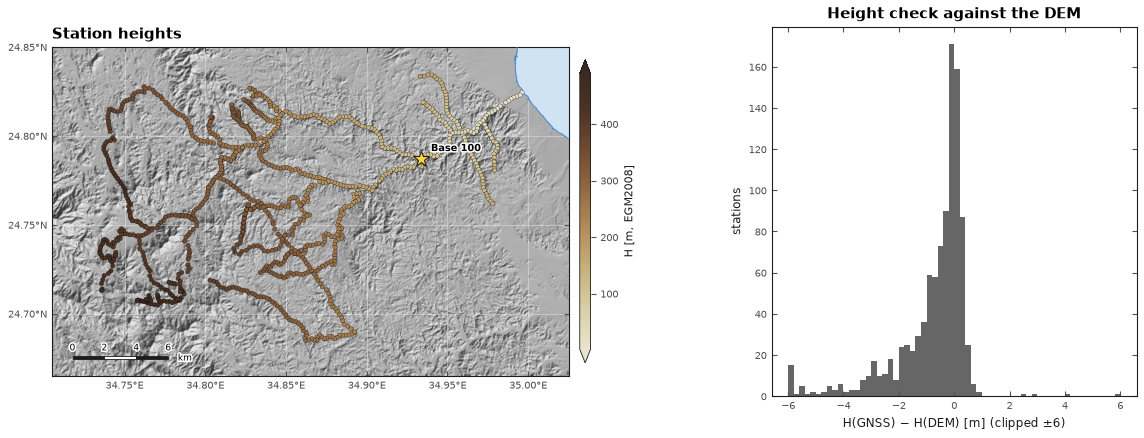

In [19]:
# 📊 RESULT
mapping.apply_map_style()
plt.rcParams.update({"figure.dpi": 100})
basemap = mapping.Basemap(dem)          # hillshade of the DEM, used by all maps below
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
basemap.draw(ax, relief_alpha=0.85)
sc = ax.scatter(f["lon"], f["lat"], c=f["H_ortho_m"], s=10, cmap=mapping.HYPSO, edgecolors="k", linewidths=0.2, zorder=10)
mapping.base100(ax, ref)
mapping.scalebar(ax)
mapping.colorbar(fig, sc, ax, "H [m, EGM2008]")
ax.set_title("Station heights", loc="left")
axes[1].hist(f["H_minus_dem_m"].clip(-6, 6), bins=60, color="0.4")
axes[1].set(xlabel="H(GNSS) − H(DEM) [m] (clipped ±6)", ylabel="stations", title="Height check against the DEM")

## 8  Base control and drift correction

Station 100 on line 0 is the field base. For each instrument the drift is modelled **piecewise linearly between
successive base-100 readings**; station 0 (hotel) adds controls through the median hotel → base-100 tie
(`base_control.base_control`). Each occupation then gets `dg100` = gravity relative to base 100.

* `TIE_MAX_HOURS`: hotel–base-100 tie legs longer than this are not used.
* `TARE_MGAL`: base-100 jumps larger than this are treated as tares, not as drift.

The second plot shows the drift model of one day; choose another `SHOW_INSTRUMENT` / `SHOW_DATE`.

In [20]:
# ✏️ PARAMETERS – edit and re-run from here
TIE_MAX_HOURS = settings.TIE_MAX_HOURS     # 4 h
TARE_MGAL = settings.TARE_MGAL             # 0.3 mGal
SHOW_INSTRUMENT, SHOW_DATE = "CG6-0640", "2026-01-18"     # day shown in the drift plot

In [21]:
# ▶ PROCESSING
(occ, ctrl, ties, tie_stats, loo, seg_rates, model_sigma,
 rate_sigma) = base_control.base_control(occ, ref, tie_max_hours=TIE_MAX_HOURS, tare_mgal=TARE_MGAL)
closures = base_control.day_closures(occ)
for df, name in ((ctrl, "10_control_points.csv"), (ties, "11_hotel_base100_ties.csv"),
                 (loo, "12_base100_leave_one_out_misclosure.csv"), (seg_rates, "12_base100_segment_rates.csv"),
                 (closures, "13_daily_closures.csv")):
    save_table(df, name)
print("drift-model uncertainty (leave-one-out) [mGal]:", {k: round(v, 4) for k, v in model_sigma.items()})
closures[["instrument", "date", "n_base100_valid", "hotel_closure_mgal", "base100_range_mgal"]]

drift-model uncertainty (leave-one-out) [mGal]: {'CG6-0313': 0.0532, 'CG6-0640': 0.0078}


,instrument,date,n_base100_valid,hotel_closure_mgal,base100_range_mgal
0,CG6-0313,2026-01-16,5,0.458185,0.557873
1,CG6-0313,2026-01-17,3,-0.150751,0.109790
2,CG6-0313,2026-01-18,2,NaN,0.137986
3,CG6-0313,2026-01-19,2,NaN,0.051898
4,CG6-0313,2026-01-20,2,-0.341437,0.158841
5,CG6-0313,2026-01-21,3,-0.114372,0.126996
6,CG6-0313,2026-01-22,3,-0.136640,0.109286
7,CG6-0313,2026-01-23,3,-0.405288,0.178583
8,CG6-0313,2026-01-24,3,-0.243225,0.244049
9,CG6-0640,2026-01-16,5,0.006238,0.010846


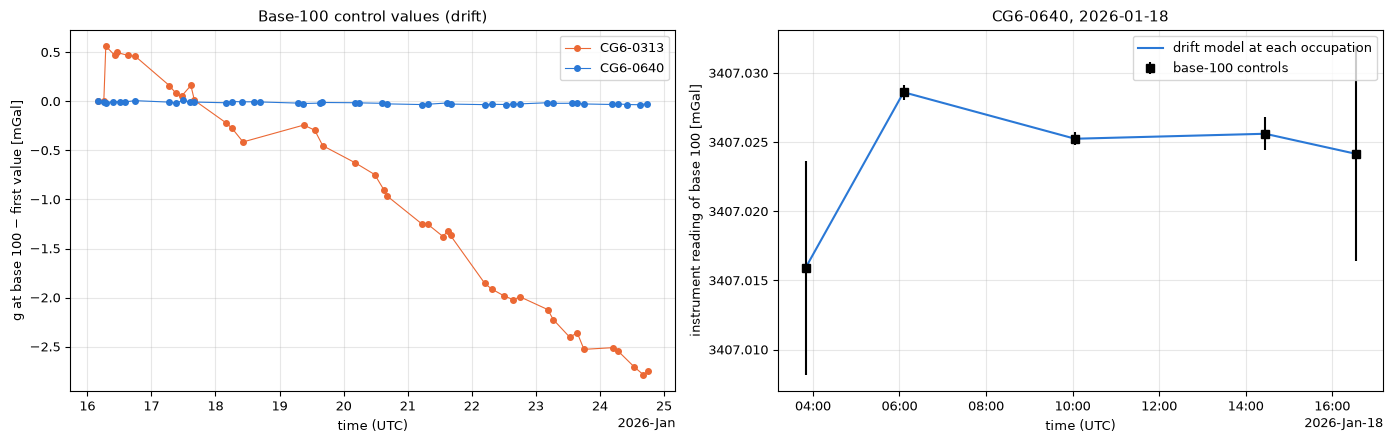

In [22]:
# 📊 RESULT
plt.rcdefaults()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for inst, d in ctrl.groupby("instrument"):
    t = pd.to_datetime(d["t"])
    ax.plot(t, d["g100"] - d["g100"].iloc[0], "o-", ms=4, lw=0.8, color=COLOR[inst], label=inst)
ax.set(xlabel="time (UTC)", ylabel="g at base 100 − first value [mGal]", title="Base-100 control values (drift)")
ax.legend()
ax = axes[1]
o = occ[(occ["instrument"] == SHOW_INSTRUMENT) & (occ["date"] == SHOW_DATE) & occ["g100_interp"].notna()].sort_values("t_mid")
c = ctrl[(ctrl["instrument"] == SHOW_INSTRUMENT) & (ctrl["date"] == SHOW_DATE)]
ax.plot(o["t_mid"], o["g100_interp"], "-", color=COLOR[SHOW_INSTRUMENT], label="drift model at each occupation")
ax.errorbar(pd.to_datetime(c["t"]), c["g100"], yerr=c["sigma"], fmt="ks", ms=6, label="base-100 controls")
ax.set(xlabel="time (UTC)", ylabel="instrument reading of base 100 [mGal]", title=f"{SHOW_INSTRUMENT}, {SHOW_DATE}")
ax.ticklabel_format(axis="y", useOffset=False)
ax.legend()
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
plt.tight_layout()

## 9  Inter-instrument calibration

The scale of #0313 relative to #0640 is estimated in two independent ways
(`instruments.scale_estimates`): from the hotel–base-100 ties, and from points measured by both instruments
(`instruments.colocated_pairs`). If they agree within 2σ, their weighted mean `k` is applied to #0313.
#0313 segments extrapolated beyond a base control are re-tied to co-located #0640 values
(`instruments.retie_extrapolated`). Set `APPLY_SCALE = False` to see the products without the scale correction.

In [23]:
# ✏️ PARAMETERS – edit and re-run from here
PAIR_MAX_SEP_M, PAIR_MAX_DH_M = 10.0, 0.5    # co-located: horizontal and height separation
APPLY_SCALE = True

In [24]:
# ▶ PROCESSING
pairs = instruments.colocated_pairs(occ, max_sep_m=PAIR_MAX_SEP_M, max_dh_m=PAIR_MAX_DH_M)
scale = instruments.scale_estimates(tie_stats, pairs)
k_apply = None
if APPLY_SCALE and "k_colocated_origin" in scale:
    z = (scale["k_colocated_origin"] - scale["k_tie"]) / np.hypot(scale["k_colocated_origin_se"], scale["k_tie_se"])
    scale["agreement_z"] = z
    if abs(z) < 2:      # the two estimates agree -> inverse-variance weighted mean
        w1, w2 = 1 / scale["k_tie_se"] ** 2, 1 / scale["k_colocated_origin_se"] ** 2
        k_apply = (w1 * scale["k_tie"] + w2 * scale["k_colocated_origin"]) / (w1 + w2)
        scale["k_applied"], scale["k_applied_se"] = k_apply, 1 / np.sqrt(w1 + w2)
retie = pd.DataFrame()
if k_apply is not None:
    occ, retie = instruments.retie_extrapolated(occ, pairs, k_apply)
save_table(pairs, "14_colocated_pairs.csv")
save_table(retie, "14_extrapolated_segment_reties.csv")
print(f"scale factor applied to CG6-0313: k = {k_apply}")
pd.Series({k: v for k, v in scale.items() if not isinstance(v, dict)}).to_frame("value")

scale factor applied to CG6-0313: k = 1.011892568547996


,value
k_tie,1.011699
k_tie_se,0.000348
k_colocated,1.012700
k_colocated_se,0.000742
offset_colocated,-0.034398
offset_colocated_se,0.022982
colocated_n,3.000000
colocated_rms_mgal,0.014639
colocated_dg_range_mgal,42.390196
k_colocated_origin,1.013556


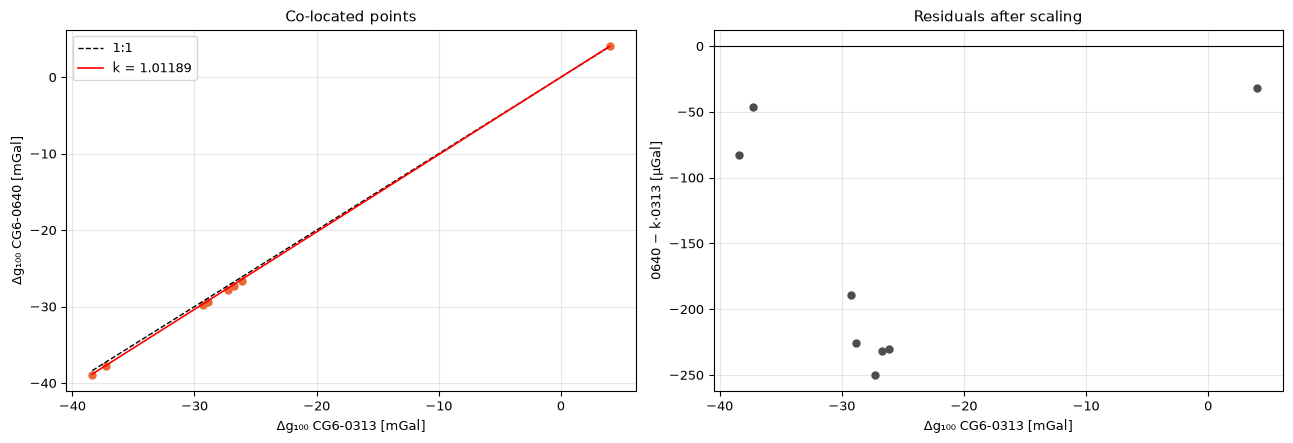

In [25]:
# 📊 RESULT
p = pairs[pairs["separation_m"] <= PAIR_MAX_SEP_M]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(p["dg100_0313"], p["dg100_0640"], "o", ms=5, color=COLOR["CG6-0313"])
x = np.linspace(p["dg100_0313"].min(), p["dg100_0313"].max(), 10)
axes[0].plot(x, x, "k--", lw=1, label="1:1")
if k_apply is not None:
    axes[0].plot(x, k_apply * x, "r-", lw=1.2, label=f"k = {k_apply:.5f}")
axes[0].set(xlabel="Δg₁₀₀ CG6-0313 [mGal]", ylabel="Δg₁₀₀ CG6-0640 [mGal]", title="Co-located points")
axes[0].legend()
k = k_apply if k_apply is not None else 1.0
axes[1].plot(p["dg100_0313"], 1000 * (p["dg100_0640"] - k * p["dg100_0313"]), "o", ms=5, color="0.3")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="Δg₁₀₀ CG6-0313 [mGal]", ylabel="0640 − k·0313 [µGal]", title="Residuals after scaling")
plt.tight_layout()

## 10  Free-air and simple Bouguer anomalies

`reductions.reductions` computes, relative to base 100 (WGS84 normal gravity γ, second-order free-air term FA):

* ΔFA = Δg₁₀₀ − [γ(φ) − γ(φ₁₀₀)] + [FA(H) − FA(H₁₀₀)]
* ΔSB(ρ) = ΔFA − 0.04193·ρ·(H − H₁₀₀), for every density in `RHO_LIST`

The plot shows how the free-air anomaly follows the topography and how the Bouguer correction removes it.
Change `RHO_SHOW` to see the effect of the density.

In [26]:
# ✏️ PARAMETERS – edit and re-run from here
RHO_LIST = settings.RHO_LIST      # densities [g/cm³] for which SB and CB columns are computed
RHO_SHOW = 2.67                   # density shown in the plots (must be in RHO_LIST)

In [27]:
# ▶ PROCESSING
st = reductions.reductions(occ, ref, k_apply=k_apply, rho_list=RHO_LIST)
s = st[st["product_ok"]]
print(f"{len(s)} stations with complete products")
s[["dg100_scaled_mgal", "H_ortho_m", "dFA_rel_mgal", f"dSB_rel_rho{RHO_SHOW:.2f}_mgal", "dFA_sigma_mgal"]].describe().round(3)

985 stations with complete products


,dg100_scaled_mgal,H_ortho_m,dFA_rel_mgal,dSB_rel_rho2.67_mgal,dFA_sigma_mgal
count,985.000,985.000,985.000,985.000,985.000
mean,-33.643,272.150,20.859,1.574,0.066
std,24.538,106.276,11.338,5.074,0.023
min,-94.373,2.232,-14.810,-14.572,0.047
25%,-46.391,220.131,18.395,-1.192,0.047
50%,-32.531,281.608,24.935,2.597,0.071
75%,-16.687,337.912,28.070,5.677,0.071
max,18.252,489.530,36.822,9.888,0.122


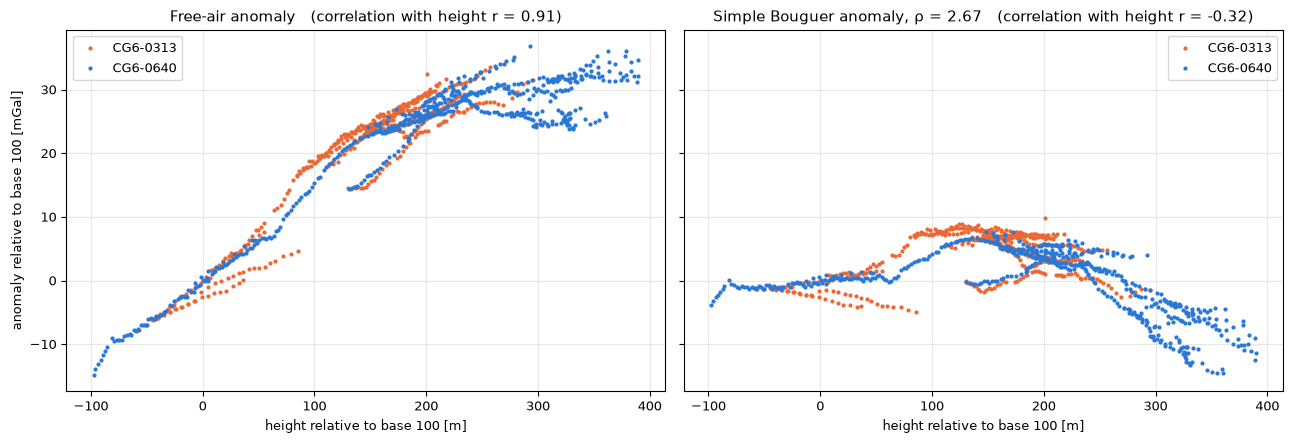

In [28]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col, title in ((axes[0], "dFA_rel_mgal", "Free-air anomaly"),
                       (axes[1], f"dSB_rel_rho{RHO_SHOW:.2f}_mgal", f"Simple Bouguer anomaly, ρ = {RHO_SHOW}")):
    for inst, d in s.groupby("instrument"):
        ax.plot(d["dh_m"], d[col], ".", ms=4, color=COLOR[inst], label=inst)
    r = np.corrcoef(s["dh_m"], s[col])[0, 1]
    ax.set(xlabel="height relative to base 100 [m]", title=f"{title}   (correlation with height r = {r:.2f})")
    ax.legend()
axes[0].set_ylabel("anomaly relative to base 100 [mGal]")
plt.tight_layout()

## 11  Terrain correction and complete Bouguer anomaly

The DEM is converted into prisms around every station (`terrain.TopoModel`, Harmonica): 1″ cells within about
±2 km, `COARSE` × `COARSE` block-averaged cells out to 22 km, Earth curvature included. For density ρ
(`reductions.terrain_stage`):

* ΔCB(ρ) = ΔFA − ρ·[g₁(station) − g₁(base 100)], where g₁ is the topographic attraction for 1 g/cm³
* TC(ρ) = ρ·(0.04193·H − g₁), the terrain correction relative to the Bouguer slab

`reductions.terrain_validation` tests the sensitivity to the zoning. This step takes about 30 s.

In [29]:
# ✏️ PARAMETERS – edit and re-run from here
COARSE = settings.COARSE        # outer-zone cell = COARSE x COARSE DEM cells (8 -> ~250 m)

In [30]:
# ▶ PROCESSING
topo = terrain.TopoModel(dem, coarse=COARSE)
st = reductions.terrain_stage(st, ref, topo, rho_list=RHO_LIST, progress=False)
terrain_check = reductions.terrain_validation(topo, st)
s = st[st["product_ok"]]
save_table(terrain_check, "22_terrain_validation.csv")
rows_out = rows.merge(occ[["occ_id", "occ_key", "role", "match_status", "gnss_uid", "match_dist_m"]], on="occ_id", how="left")
save_table(rows_out.drop(columns=["t"], errors="ignore"), "05_rows_qc.csv")
save_table(occ, "15_occupations.csv")
save_table(st, "16_field_stations_relative.csv")
display(s[["TC_rho2.67_mgal", f"dCB_rel_rho{RHO_SHOW:.2f}_mgal"]].describe().round(3))
terrain_check.round(4)

,TC_rho2.67_mgal,dCB_rel_rho2.67_mgal
count,985.000,985.000
mean,0.942,1.393
std,0.379,4.901
min,0.210,-13.953
25%,0.690,-1.203
50%,0.882,2.259
75%,1.156,5.452
max,2.779,9.418


,occ_key,TC1,g1,d_finer_outer_and_wider_inner,d_outer_radius_20km,d_station_height_plus_0_5m
0,CG6-0640|2026-01-16|L1|S1,0.0785,0.0151,-0.0003,0.0030,0.0213
1,CG6-0640|2026-01-23|L1|S471,0.1834,12.9592,-0.0007,-0.0067,0.0231
2,CG6-0313|2026-01-16|L3|S24,0.2276,10.5736,-0.0007,-0.0027,0.0245
3,CG6-0640|2026-01-18|L1|S148,0.2643,13.9361,-0.0012,-0.0073,0.0221
4,CG6-0640|2026-01-22|L1|S362,0.2885,14.1211,-0.0010,-0.0085,0.0231
5,CG6-0313|2026-01-16|L2|S3,0.3176,4.2855,-0.0006,0.0024,0.0264
6,CG6-0313|2026-01-19|L7|S7,0.3416,9.7299,-0.0006,-0.0002,0.0270
7,CG6-0640|2026-01-16|L1|S43,0.3708,3.8360,-0.0006,0.0028,0.0261
8,CG6-0640|2026-01-20|L1|S260,0.4204,16.2630,-0.0019,-0.0140,0.0223
9,CG6-0313|2026-01-16|L3|S4,0.4737,7.5832,-0.0007,0.0010,0.0289


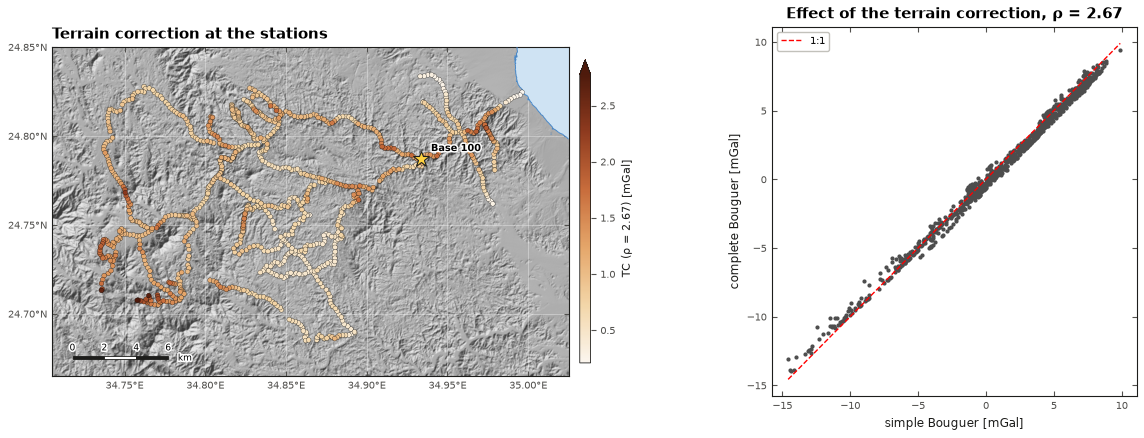

In [31]:
# 📊 RESULT
mapping.apply_map_style()
plt.rcParams.update({"figure.dpi": 100})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
basemap.draw(ax, relief_alpha=0.85)
o = s.sort_values("TC_rho2.67_mgal")
sc = ax.scatter(o["lon"], o["lat"], c=o["TC_rho2.67_mgal"], s=12, cmap=mapping.TC_CMAP, edgecolors="k",
                linewidths=0.2, zorder=10)
mapping.base100(ax, ref)
mapping.scalebar(ax)
mapping.colorbar(fig, sc, ax, "TC (ρ = 2.67) [mGal]", extend="max")
ax.set_title("Terrain correction at the stations", loc="left")
ax = axes[1]
ax.plot(s[f"dSB_rel_rho{RHO_SHOW:.2f}_mgal"], s[f"dCB_rel_rho{RHO_SHOW:.2f}_mgal"], ".", ms=4, color="0.3")
lim = [s[f"dSB_rel_rho{RHO_SHOW:.2f}_mgal"].min(), s[f"dSB_rel_rho{RHO_SHOW:.2f}_mgal"].max()]
ax.plot(lim, lim, "r--", lw=1, label="1:1")
ax.set(xlabel="simple Bouguer [mGal]", ylabel="complete Bouguer [mGal]", title=f"Effect of the terrain correction, ρ = {RHO_SHOW}")
ax.legend()

## 12  Reduction density: Nettleton method

The stations of each line are cut into continuous profiles (`density.build_profiles`). For each profile the
density is found at which the Bouguer anomaly no longer correlates with the topography (`density.run_nettleton`,
for the simple and the complete Bouguer correction). Short 3 km windows (`density.window_nettleton`) and a
weighted consensus (`density.density_consensus`) summarise all estimates.

The plot shows one profile: change `SHOW_PROFILE` (see the table of profile ids) and `SHOW_DENSITIES`.

In [32]:
# ✏️ PARAMETERS – edit and re-run from here
PROFILE_SPLIT = dict(max_step_m=1000.0, min_n=15, min_relief_m=40.0)    # profile segmentation
WINDOW = dict(window_m=3000.0, min_n=10, min_relief_m=30.0)            # moving windows
SHOW_PROFILE = "N-L1-1-148"
SHOW_DENSITIES = (2.0, 2.4, 2.67, 3.0)

In [33]:
# ▶ PROCESSING
prof, prof_summary = density.build_profiles(st, **PROFILE_SPLIT)
sweeps, net = density.run_nettleton(prof, prof_summary)
win = density.window_nettleton(prof, **WINDOW)
day_boundary = density.day_boundary_check(prof, datum_days)
consensus = density.density_consensus(net, win)
for df, name in ((prof, "17_profiles_stations.csv"), (prof_summary, "17_profiles_summary.csv"),
                 (sweeps, "18_nettleton_sweeps.csv"), (net, "18_nettleton_results.csv"),
                 (win, "19_nettleton_windows.csv"), (day_boundary, "20_day_boundary_height_check.csv"),
                 (consensus, "23_density_consensus.csv")):
    save_table(df, name)
display(consensus.round(3))
net[net["method"] == "complete"][["profile_id", "n_used", "relief_m", "rho_zero_corr", "rho_regression",
                                  "rho_boot_p2_5", "rho_boot_p97_5"]].round(2)

,set,method,n,weighted_mean,weighted_se,median,p25,p75,chi2,dof,p_value,birge_ratio,weighted_se_scaled
0,profiles,simple,15,2.300,0.041,2.927,1.640,3.182,1483.402,14,0.0,10.294,0.418
1,profiles,complete,19,2.523,0.032,2.039,1.361,2.927,964.497,18,0.0,7.320,0.233
2,3km_windows,simple,16,3.053,0.077,3.149,2.102,3.431,57.449,15,0.0,1.957,0.150
3,3km_windows,complete,32,2.786,0.044,2.529,1.572,3.017,179.948,31,0.0,2.409,0.107


,profile_id,n_used,relief_m,rho_zero_corr,rho_regression,rho_boot_p2_5,rho_boot_p97_5
1,N-L1-1-148,147,336.44,2.49,0.78,-1.27,4.62
3,N-L1-149-225,76,237.41,NaN,-1.20,-1.62,-0.21
5,N-L1-226-245,20,68.80,2.38,2.04,-5.72,2.81
7,N-L1-246-300,54,88.68,NaN,-2.55,-3.80,-0.63
9,N-L1-301-335,22,77.80,2.99,2.96,-4.91,3.99
11,N-L1-358-418,57,142.83,NaN,1.70,0.66,5.08
13,N-L1-433-501,69,161.93,2.89,2.91,2.18,3.52
15,N-L1-502-517,16,104.77,NaN,1.53,-0.35,2.97
17,N-L1-541-557,16,54.99,2.80,2.82,2.19,6.61
19,O-L10-1-25,24,101.28,NaN,0.62,-0.95,2.28


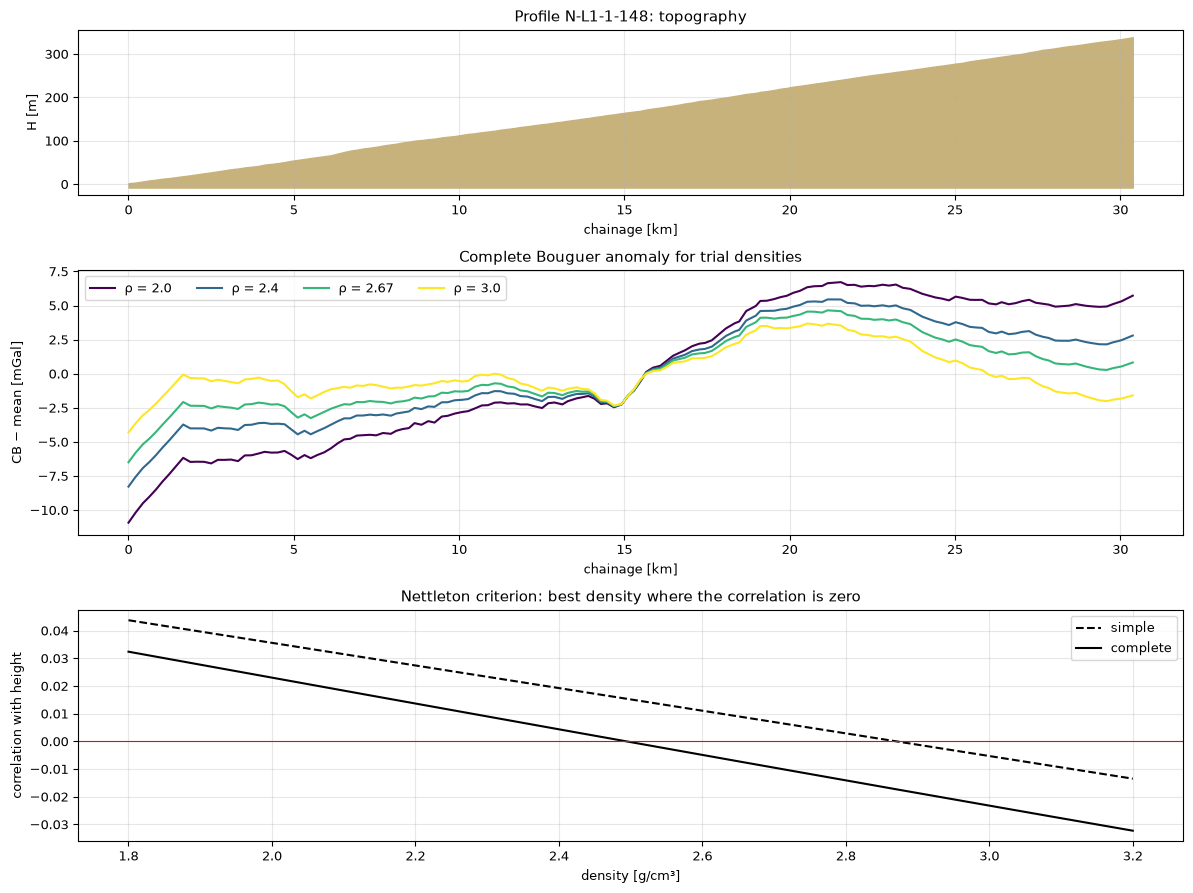

In [34]:
# 📊 RESULT
plt.rcdefaults()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
p = prof[prof["profile_id"] == SHOW_PROFILE].sort_values("chainage_m")
x = p["chainage_m"] / 1000
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=False, gridspec_kw={"height_ratios": [1, 1.6, 1.4]})
axes[0].fill_between(x, p["H_ortho_m"].min() - 10, p["H_ortho_m"], color="#c8b27c")
axes[0].set(ylabel="H [m]", title=f"Profile {SHOW_PROFILE}: topography", xlabel="chainage [km]")
cmap = plt.cm.viridis
for i, rho in enumerate(SHOW_DENSITIES):
    cb = p["dFA_rel_mgal"] - rho * p["u_topo_mgal_per_gcc"]
    axes[1].plot(x, cb - cb.mean(), "-", color=cmap(i / max(len(SHOW_DENSITIES) - 1, 1)), label=f"ρ = {rho}")
axes[1].set(ylabel="CB − mean [mGal]", xlabel="chainage [km]", title="Complete Bouguer anomaly for trial densities")
axes[1].legend(ncol=len(SHOW_DENSITIES))
for method, ls in (("simple", "--"), ("complete", "-")):
    sw = sweeps[(sweeps["profile_id"] == SHOW_PROFILE) & (sweeps["method"] == method)]
    axes[2].plot(sw["rho"], sw["corr_detrended"], ls, color="k", label=method)
axes[2].axhline(0, color="r", lw=0.8)
axes[2].set(xlabel="density [g/cm³]", ylabel="correlation with height",
            title="Nettleton criterion: best density where the correlation is zero")
axes[2].legend()
plt.tight_layout()

## 13  Gridding and anomaly maps

The station values are gridded in UTM 36N (`gmaps.Gridder`): block median, linear trend and damped biharmonic
spline (Verde), blanked farther than 2 km from the stations. The maps are drawn here with the shared map tools
(`mapping.Basemap`, `mapping.scalebar`, …), so colours, density and grid spacing can be changed freely.
`RHO_MAP` can be any density, because the complete Bouguer anomaly is recomputed from ΔFA and the unit
topographic effect.

In [35]:
# ✏️ PARAMETERS – edit and re-run from here
RHO_MAP = 2.67              # any reduction density [g/cm³]
GRID_SPACING_M = 100.0      # grid node spacing
DAMPING = 1e-7              # spline damping (larger = smoother)
CONTOUR_STEP = 1.0          # mGal

In [36]:
# ▶ PROCESSING
s = st[st["product_ok"]].copy()
s["SB_map"] = s["dFA_rel_mgal"] - RHO_MAP * s["u_slab_mgal_per_gcc"]
s["CB_map"] = s["dFA_rel_mgal"] - RHO_MAP * s["u_topo_mgal_per_gcc"]
gridder = gmaps.Gridder(spacing=GRID_SPACING_M)
grids = {}
for col in ("dFA_rel_mgal", "SB_map", "CB_map"):
    LON, LAT, Z, grid = gridder.grid(s["lon"], s["lat"], s[col], damping=DAMPING)
    grids[col] = (LON, LAT, Z)
print("grid size:", Z.shape, " cross-validation rms of CB [mGal]:",
      round(gridder.cv_score(s["lon"], s["lat"], s["CB_map"], damping=DAMPING), 3))

grid size: (210, 327)  cross-validation rms of CB [mGal]: 0.644


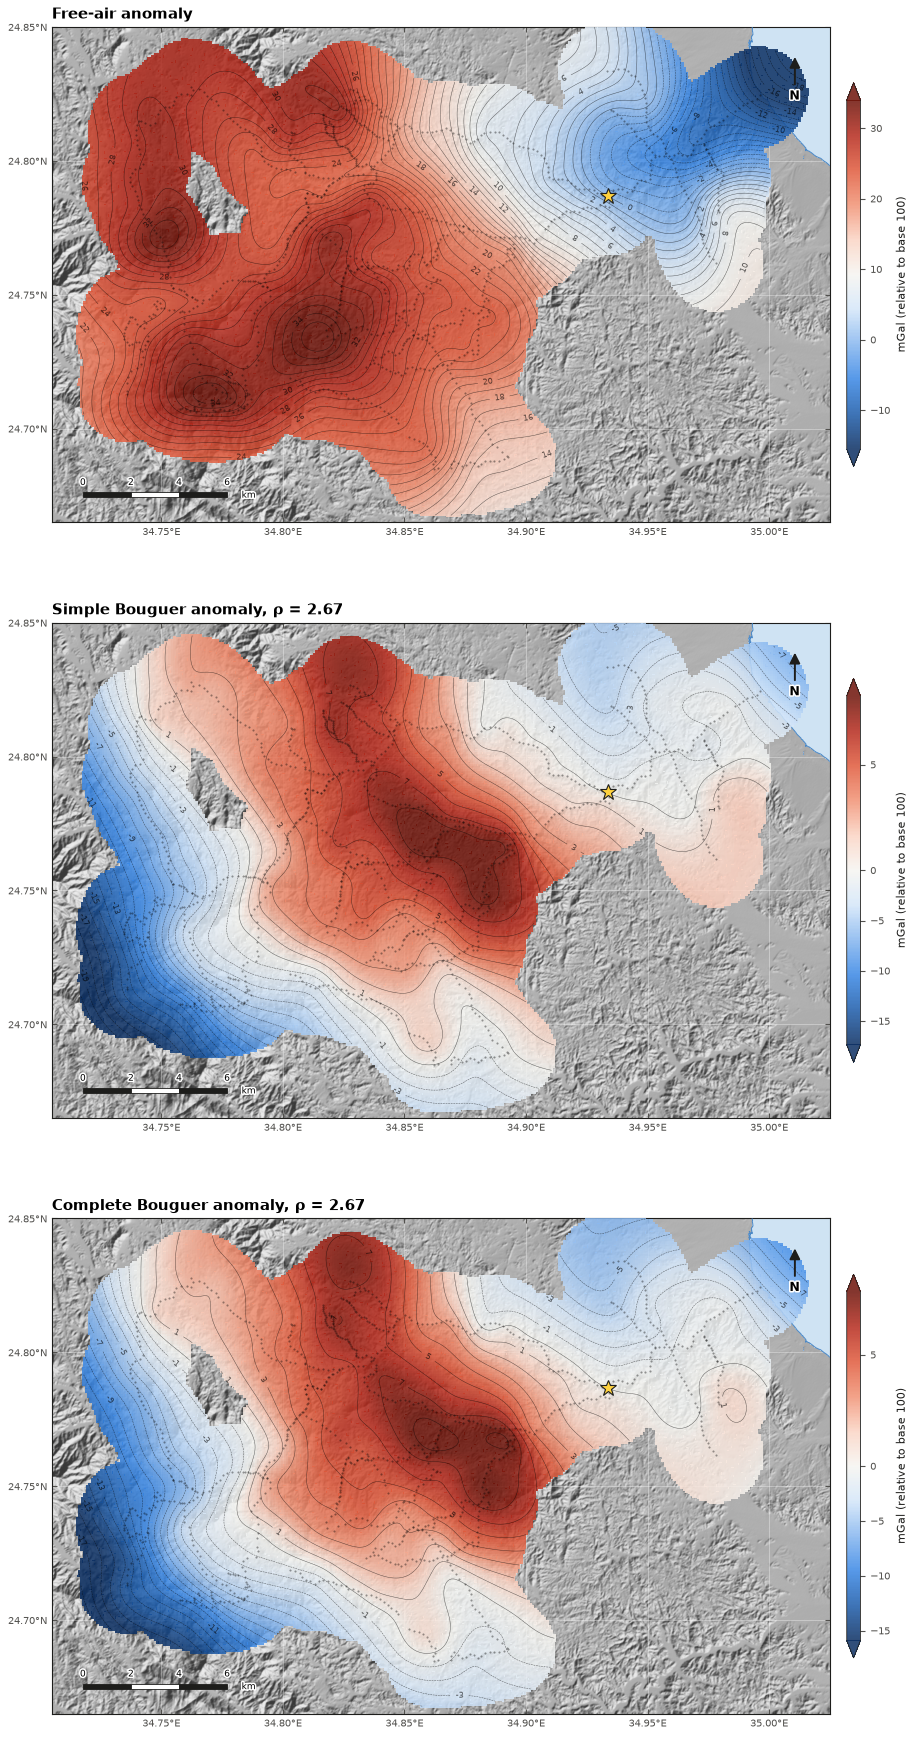

In [37]:
# 📊 RESULT
mapping.apply_map_style()
plt.rcParams.update({"figure.dpi": 100})


def anomaly_map(ax, LON, LAT, Z, title, center=None):
    """One gridded anomaly map on the DEM relief (edit freely)."""
    from matplotlib.colors import Normalize, TwoSlopeNorm
    lo, hi = np.nanpercentile(Z, [1, 99])
    norm = TwoSlopeNorm(center, lo, hi) if center is not None and lo < center < hi else Normalize(lo, hi)
    basemap.draw(ax, relief_alpha=0.85)
    m = ax.pcolormesh(LON, LAT, Z, cmap=mapping.ANOM, norm=norm, shading="auto", alpha=0.85, zorder=5)
    levels = np.arange(np.floor(np.nanmin(Z)), np.ceil(np.nanmax(Z)) + CONTOUR_STEP, CONTOUR_STEP)
    cs = ax.contour(LON, LAT, Z, levels=levels, colors="k", linewidths=0.35, alpha=0.6, zorder=6)
    ax.clabel(cs, cs.levels[::2], fmt="%g", fontsize=6)
    ax.plot(s["lon"], s["lat"], ".", ms=1, color="k", alpha=0.4, zorder=7)
    mapping.base100(ax, ref, label=False)
    mapping.scalebar(ax)
    mapping.north_arrow(ax)
    mapping.colorbar(ax.figure, m, ax, "mGal (relative to base 100)", shrink=0.7)
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(3, 1, figsize=(10, 18))
anomaly_map(axes[0], *grids["dFA_rel_mgal"], "Free-air anomaly")
anomaly_map(axes[1], *grids["SB_map"], f"Simple Bouguer anomaly, ρ = {RHO_MAP}", center=0)
anomaly_map(axes[2], *grids["CB_map"], f"Complete Bouguer anomaly, ρ = {RHO_MAP}", center=0)
plt.tight_layout()

## 14  Export the results and publication figures

Writes the final products to `outputs/deliverables/`: an Excel workbook with the final station sheet and all QC
sheets, plus CSV, GeoJSON and KML (`export.write_workbook`, `export.write_geojson`, `export.write_kml`), and the
run summary `outputs/summary.json`. With `MAKE_PUBLICATION_FIGURES = True`, all QC figures, the 400 dpi maps,
the grids and the Nettleton sheets are also written (`figures.make_all`, about 2 minutes).

In [38]:
# ✏️ PARAMETERS – edit and re-run from here
MAKE_PUBLICATION_FIGURES = True

In [39]:
# ▶ PROCESSING
DELIVERABLE_DIR = os.path.join(OUT_DIR, "deliverables")
os.makedirs(DELIVERABLE_DIR, exist_ok=True)
summary = dict(
    height_datum=height_datum, scale=scale, retie=retie.to_dict("records"),
    rows=int(len(rows)), rows_accepted=int(rows["accepted"].sum()),
    rows_rejected_by_reason=rows.loc[~rows["accepted"], "reject_reasons"].value_counts().to_dict(),
    occupations=int(len(occ)), occupations_usable=int(occ["usable"].sum()),
    match_status=occ.groupby(["instrument", "match_status"]).size().rename("n").reset_index().to_dict("records"),
    day_of_date=day_of_date, master_check=master_check, ref=ref, tie_stats=tie_stats,
    model_sigma=model_sigma, rate_sigma=rate_sigma, products=int(st["product_ok"].sum()))
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2,
              default=lambda o: o.item() if isinstance(o, (np.generic,)) else str(o))

ctx = dict(st=st, prof=prof, net=net, sweeps=sweeps, win=win, cons=consensus, ctrl=ctrl, ties=ties,
           closures=closures, sc=scale, pairs=pairs, hchk=height_check, tval=terrain_check, occ=occ, df=rows, meta=meta)
final = export.write_workbook(os.path.join(DELIVERABLE_DIR, "Wadi_Ghadir_Gravity_Results.xlsx"), ctx)
final.to_csv(os.path.join(DELIVERABLE_DIR, "Wadi_Ghadir_Final_Stations.csv"), index=False, float_format="%.6f")
export.write_geojson(os.path.join(DELIVERABLE_DIR, "Wadi_Ghadir_Final_Stations.geojson"), final)
export.write_kml(os.path.join(DELIVERABLE_DIR, "Wadi_Ghadir_Final_Stations.kml"), final)
print("deliverables:", sorted(os.listdir(DELIVERABLE_DIR)))

if MAKE_PUBLICATION_FIGURES:
    fig_ctx = dict(df=rows, occ=occ, st=st, P=gnss_points, ctrl=ctrl, ties=ties, loo=loo, closures=closures,
                   pairs=pairs, sc=scale, retie=retie, win=win, dbc=day_boundary, datum_days=datum_days,
                   closures_tab=closures, prof=prof, prof_sum=prof_summary, sweeps=sweeps, net=net,
                   datum_marks=datum_marks, ref=ref, tide=tide_check, cons=consensus, hchk=height_check,
                   tval=terrain_check, dem=dem, geoid=geoid, model=topo)
    cv = figures.make_all(fig_ctx, os.path.join(OUT_DIR, "figures"))
    print("publication figures written; gridding cross-validation [mGal]:", {k: round(v, 3) for k, v in cv.items()})
final.head()

deliverables: ['Wadi_Ghadir_Final_Stations.csv', 'Wadi_Ghadir_Final_Stations.geojson', 'Wadi_Ghadir_Final_Stations.kml', 'Wadi_Ghadir_Gravity_Results.xlsx', 'Wadi_Ghadir_Magnetic_Results.xlsx']


  maps ...


  Nettleton figures ...


publication figures written; gridding cross-validation [mGal]: {'dg100_scaled_mgal': 1.834, 'dFA_rel_mgal': 1.161, 'dSB_rel_rho2.67_mgal': 0.65, 'dCB_rel_rho2.67_mgal': 0.644}


,Station_UID,Instrument,Date,Line,Station,GNSS_Point,GNSS_Source,Match_Dist_m,Lat_deg,Lon_deg,UTM36N_E_m,UTM36N_N_m,Time_UTC,N_Readings,h_ellip_m,...,CB_rel_2.30_mGal,CB_rel_2.40_mGal,CB_rel_2.50_mGal,CB_rel_2.60_mGal,CB_rel_2.67_mGal,CB_rel_2.70_mGal,CB_rel_2.80_mGal,CB_rel_2.90_mGal,CB_rel_3.00_mGal,Dist_to_Sea_km,Drift_Mode,Scale_k_applied,Day_Height_Shift_m,Match_Status,QC_Warnings
0,CG6-0313|2026-01-16|L2|S1,CG6-0313,2026-01-16,2,1,2-1,results.zip/day1.xlsx,4.920152,24.784778,34.934282,695550.757540,2.742501e+06,2026-01-16 07:14:27,2,115.146,...,0.299045,0.289874,0.280703,0.271531,0.265111,0.262360,0.253189,0.244018,0.234846,7.797418,INTERPOLATED,1.011893,0.0,MATCHED,
1,CG6-0313|2026-01-16|L2|S2,CG6-0313,2026-01-16,2,2,2-2,results.zip/day1.xlsx,4.280312,24.782753,34.934027,695528.101933,2.742276e+06,2026-01-16 07:21:03,2,119.294,...,0.645473,0.602274,0.559075,0.515877,0.485637,0.472678,0.429479,0.386280,0.343082,7.935325,INTERPOLATED,1.011893,0.0,MATCHED,
2,CG6-0313|2026-01-16|L2|S3,CG6-0313,2026-01-16,2,3,2-3,results.zip/day1.xlsx,2.076470,24.783221,34.932416,695364.429888,2.742326e+06,2026-01-16 07:26:30,2,121.670,...,0.581121,0.529334,0.477547,0.425759,0.389508,0.373972,0.322185,0.270397,0.218610,8.047691,INTERPOLATED,1.011893,0.0,MATCHED,
3,CG6-0313|2026-01-16|L2|S4,CG6-0313,2026-01-16,2,4,2-4,results.zip/day1.xlsx,1.936928,24.783537,34.930516,695171.838862,2.742358e+06,2026-01-16 07:32:39,2,126.306,...,0.682898,0.605886,0.528873,0.451861,0.397952,0.374848,0.297836,0.220824,0.143811,8.189540,INTERPOLATED,1.011893,0.0,MATCHED,
4,CG6-0313|2026-01-16|L2|S5,CG6-0313,2026-01-16,2,5,2-5,results.zip/day1.xlsx,0.960256,24.782445,34.928885,695008.646993,2.742235e+06,2026-01-16 07:37:49,2,129.586,...,0.910266,0.818407,0.726547,0.634688,0.570387,0.542829,0.450970,0.359111,0.267252,8.394074,INTERPOLATED,1.011893,0.0,MATCHED,


`map10_complete_bouguer_density_panel.png`

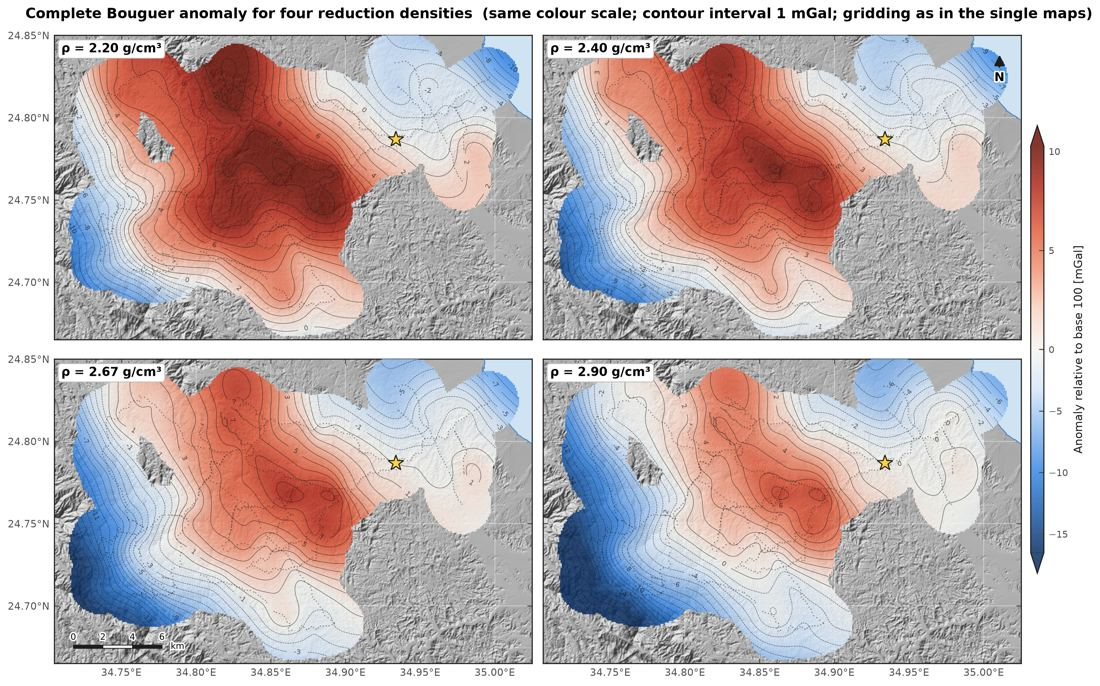

In [40]:
# 📊 RESULT
# one of the 400 dpi publication maps (down-scaled for the notebook)
from wghadir.common.display import show_figure
if MAKE_PUBLICATION_FIGURES:
    show_figure(os.path.join(OUT_DIR, "maps", "map10_complete_bouguer_density_panel.png"))

---
**Results:** `outputs/deliverables/` (final sheets), `outputs/tables/` (all intermediate tables),
`outputs/maps/`, `outputs/grids/`, `outputs/figures/` and `outputs/nettleton/`.

*Prepared by Dr. Mohamed Sobh, LIAG.*